# Weather dashboard (simulated from the Open-Meteo history)

A mock-up of what a CAI-Lamity weather dashboard could show for a city on a given day, built from `datasets/`. It replays history: pick a city and an "as of" date and the dashboard shows what a resident would have seen that day.

**This is a simulation.** The risk levels use simple illustrative thresholds (set in section 2), not PAGASA's warnings. Real warnings must always come from PAGASA and local DRRMOs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir())  # repo root, wherever the notebook lives
DATA = REPO / "datasets"

features = pd.read_csv(DATA / "ncr_flood_features_daily.csv", parse_dates=["date"])
weather = pd.read_csv(DATA / "ncr_weather_daily_2020-2026.csv", parse_dates=["date"])
locations = pd.read_csv(DATA / "ncr_locations.csv", encoding="utf-8-sig")  # file starts with a BOM

features["city"] = features["location_id"].map(locations.set_index("location_id")["city"])
weather["city"] = weather["location_id"].map(locations.set_index("location_id")["city"])

## 1. One row per city per day
Several location points sit in the same city, so they are combined: rain is averaged (points in a city share the same weather grid cell), discharge is averaged, gusts and the wet streak take the maximum.

In [2]:
daily = (
    features.groupby(["city", "date"])
    .agg(
        rain_mm=("precipitation_sum_mm", "mean"),
        rain_1h_mm=("rain_max_1h_mm", "mean"),
        rain_3d_mm=("rain_3d_mm", "mean"),
        rain_7d_mm=("rain_7d_mm", "mean"),
        rain_14d_mm=("rain_14d_mm", "mean"),
        wet_streak_days=("wet_streak_days", "max"),
        discharge=("river_discharge_m3s", "mean"),
        discharge_pctile=("discharge_pctile", "mean"),
        gust_kmh=("wind_gusts_10m_max_kmh", "max"),
    )
    .reset_index()
)

# Temperature: use the complete hourly-derived columns (the daily ones are missing for 2020-2021).
temperature = (
    weather.groupby(["city", "date"])
    .agg(temp_max_c=("temperature_2m_max_from_hourly_c", "mean"), temp_min_c=("temperature_2m_min_from_hourly_c", "mean"))
    .reset_index()
)
daily = daily.merge(temperature, on=["city", "date"])
CITIES = sorted(daily["city"].unique())
LAST_DAY = daily["date"].max()
print(len(daily), "city-days |", ", ".join(CITIES), "| last day", LAST_DAY.date())

17423 city-days | Las Piñas, Manila, Marikina, Pasig, Quezon City, Taguig, Valenzuela | last day 2026-10-24


## 2. Risk level (illustrative)
Three signals, each mapped to a band; the overall level is the highest band. Bands are for this mock-up only:

| Signal | Yellow | Orange | Red |
|---|---|---|---|
| Rain in the heaviest hour (mm) | 7.5 | 15 | 30 |
| Rain over 3 days (mm) | 50 | 100 | 150 |
| River discharge percentile (vs. this city's history) | 0.90 | 0.95 | 0.99 |

In [3]:
LEVELS = ["Normal", "Yellow", "Orange", "Red"]
BAND_EDGES = {  # signal -> (yellow, orange, red) lower limits
    "rain_1h_mm": (7.5, 15, 30),
    "rain_3d_mm": (50, 100, 150),
    "discharge_pctile": (0.90, 0.95, 0.99),
}
SIGNAL_NAMES = {"rain_1h_mm": "hourly rain", "rain_3d_mm": "3-day rain", "discharge_pctile": "river discharge"}


def band(value, edges):
    """0 = normal, 1 = yellow, 2 = orange, 3 = red."""
    return sum(value >= edge for edge in edges)


def risk_for_day(row):
    """Return ``(level index, [reasons])`` for one city-day."""
    bands = {signal: band(row[signal], edges) for signal, edges in BAND_EDGES.items()}
    level = max(bands.values())
    reasons = [f"{SIGNAL_NAMES[s]} {LEVELS[b]}" for s, b in bands.items() if b == level and level > 0]
    return level, reasons


# Status colours are reserved for risk; each is always shown with its text label too.
LEVEL_COLORS = {0: "#2f7d4f", 1: "#c99a00", 2: "#d9641c", 3: "#c0322b"}

daily["risk_level"] = daily.apply(lambda row: risk_for_day(row)[0], axis=1)
daily.groupby("city")["risk_level"].apply(lambda s: s.map(dict(enumerate(LEVELS))).value_counts()).unstack(fill_value=0)[LEVELS]

Las Piñas,Normal,Yellow,Orange,Red
city,,,,
Las Piñas,2156,210,99,24
Manila,2115,245,105,24
Marikina,1984,343,126,36
Pasig,2088,259,111,31
Quezon City,2096,255,108,30
Taguig,2082,267,106,34
Valenzuela,2104,253,103,29


## 3. The dashboard

In [4]:
INK = "#1c1b19"
MUTED = "#6b6a65"
CARD = "#f6f5f2"
BLUE = "#2a78d6"
GRID = "#d9d8d4"
DARK_BLUE = "#173f73"


def style_axis(axis):
    """Quiet chart axes: no frame on top/right, light grid, small text."""
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#8a8984")
    axis.grid(color=GRID, linewidth=0.6)
    axis.set_axisbelow(True)
    axis.tick_params(labelsize=8, colors=MUTED)


def draw_tile(axis, label, value, sub, accent=None):
    """A KPI tile: small label, big number, one line of context."""
    axis.set_axis_off()
    axis.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="square,pad=0",
                                  transform=axis.transAxes, facecolor=CARD, edgecolor=GRID, linewidth=0.8))
    if accent:
        axis.add_patch(FancyBboxPatch((0.02, 0.04), 0.025, 0.92, boxstyle="square,pad=0",
                                      transform=axis.transAxes, facecolor=accent, edgecolor="none"))
    axis.text(0.1, 0.78, label, transform=axis.transAxes, fontsize=9, color=MUTED)
    axis.text(0.1, 0.40, value, transform=axis.transAxes, fontsize=21, fontweight="bold", color=INK)
    axis.text(0.1, 0.13, sub, transform=axis.transAxes, fontsize=8, color=MUTED)


def percentile_label(value):
    """Describe a discharge percentile in words."""
    if value >= 0.995:
        return "top 1% of its history"
    return f"{value * 100:.0f}th percentile of its history"


def render_dashboard(city, as_of):
    """Draw the whole dashboard for ``city`` as it would look on ``as_of``."""
    as_of = pd.Timestamp(as_of)
    city_days = daily[daily["city"] == city].set_index("date")
    today = city_days.loc[as_of]
    level, reasons = risk_for_day(today)
    history = city_days.loc[as_of - pd.Timedelta(days=29): as_of]
    peers = daily[daily["date"] == as_of].set_index("city")

    fig = plt.figure(figsize=(15, 12.5), facecolor="white")
    grid = GridSpec(5, 5, figure=fig, height_ratios=[0.8, 1.0, 2.6, 2.6, 2.4], hspace=0.6, wspace=0.28,
                    left=0.05, right=0.97, top=0.97, bottom=0.07)

    # --- Header: city, date, risk badge -------------------------------------------------
    header = fig.add_subplot(grid[0, :])
    header.set_axis_off()
    header.text(0.0, 0.72, f"{city}", fontsize=26, fontweight="bold", color=INK, transform=header.transAxes)
    header.text(0.0, 0.18, f"Weather and flood watch  |  as of {as_of:%A, %d %B %Y}  |  simulated from Open-Meteo history",
                fontsize=10, color=MUTED, transform=header.transAxes)
    header.add_patch(FancyBboxPatch((0.66, 0.1), 0.34, 0.82, boxstyle="square,pad=0",
                                    transform=header.transAxes, facecolor=LEVEL_COLORS[level], edgecolor="none"))
    header.text(0.83, 0.62, f"{LEVELS[level].upper()}  LEVEL" if level else "NORMAL", ha="center", fontsize=17,
                fontweight="bold", color="white", transform=header.transAxes)
    header.text(0.83, 0.27, ("Triggered by: " + ", ".join(reasons)) if reasons else "No signal above its yellow limit",
                ha="center", fontsize=9, color="white", transform=header.transAxes)

    # --- KPI tiles ----------------------------------------------------------------------
    tiles = [
        ("Rain today", f"{today.rain_mm:.0f} mm", f"heaviest hour {today.rain_1h_mm:.1f} mm", None),
        ("Rain, last 3 days", f"{today.rain_3d_mm:.0f} mm", f"7 days {today.rain_7d_mm:.0f} | 14 days {today.rain_14d_mm:.0f} mm", None),
        ("River discharge", f"{today.discharge:,.1f} m3/s" if today.discharge < 10 else f"{today.discharge:,.0f} m3/s", percentile_label(today.discharge_pctile), None),
        ("Peak gust", f"{today.gust_kmh:.0f} km/h", "strongest at any point in the city", None),
        ("Temperature", f"{today.temp_max_c:.0f} / {today.temp_min_c:.0f} C", f"rain on {today.wet_streak_days:.0f} days in a row", None),
    ]
    for column, (label, value, sub, accent) in enumerate(tiles):
        draw_tile(fig.add_subplot(grid[1, column]), label, value, sub, accent)

    # --- 30-day rain with the 3-day total ------------------------------------------------
    rain_axis = fig.add_subplot(grid[2, :3])
    rain_axis.bar(history.index, history["rain_mm"], color=BLUE, width=0.75)
    rain_axis.bar(history.index[-1:], history["rain_mm"].iloc[-1:], color=DARK_BLUE, width=0.75)
    rain_axis.set_title("Daily rain, last 30 days (mm)", loc="left", fontsize=11, fontweight="bold", color=INK)
    style_axis(rain_axis)
    rain_axis.grid(axis="x", visible=False)
    rain_axis.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
    rain_axis.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=7))  # one label a week, so none overlap

    # --- 30-day discharge (own chart, own scale) ------------------------------------------
    flow_axis = fig.add_subplot(grid[2, 3:])
    flow_axis.plot(history.index, history["discharge"], color=INK, linewidth=1.6)
    flow_axis.fill_between(history.index, history["discharge"], color=BLUE, alpha=0.15)
    flow_axis.scatter(history.index[-1:], history["discharge"].iloc[-1:], color=DARK_BLUE, s=36, zorder=3,
                      edgecolor="white", linewidth=1.5)
    flow_axis.set_title("River discharge, last 30 days (m3/s)", loc="left", fontsize=11, fontweight="bold", color=INK)
    style_axis(flow_axis)
    flow_axis.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
    flow_axis.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=7))  # one label a week, so none overlap

    # --- Cities today ---------------------------------------------------------------------
    ranking = peers["rain_mm"].sort_values()
    city_axis = fig.add_subplot(grid[3, :2])
    bar_colors = [DARK_BLUE if name == city else BLUE for name in ranking.index]
    city_axis.barh(ranking.index, ranking.values, color=bar_colors, height=0.62)
    for position, (name, value) in enumerate(ranking.items()):
        city_axis.text(value, position, f"  {value:.0f}", va="center", fontsize=8, color=INK)
    city_axis.set_title("Rain today by city (mm)", loc="left", fontsize=11, fontweight="bold", color=INK)
    style_axis(city_axis)
    city_axis.grid(axis="y", visible=False)
    city_axis.set_xlim(0, max(ranking.max() * 1.18, 1))

    # --- Last 7 days by city (heat grid) --------------------------------------------------
    week = daily[daily["date"].between(as_of - pd.Timedelta(days=6), as_of)]
    week_grid = week.pivot(index="city", columns="date", values="rain_mm").reindex(CITIES)
    heat_axis = fig.add_subplot(grid[3, 2:])
    image = heat_axis.imshow(week_grid.values, aspect="auto", cmap="Blues", vmin=0, vmax=max(60, np.nanmax(week_grid.values)))
    heat_axis.set_yticks(range(len(CITIES)), CITIES, fontsize=8)
    heat_axis.set_xticks(range(7), [f"{d:%a %d}" for d in week_grid.columns], fontsize=8)
    heat_axis.grid(False)
    for row in range(week_grid.shape[0]):
        for column in range(week_grid.shape[1]):
            value = week_grid.values[row, column]
            heat_axis.text(column, row, f"{value:.0f}", ha="center", va="center", fontsize=8,
                           color="white" if value > 0.55 * image.get_clim()[1] else INK)
    heat_axis.set_title("Rain by city, last 7 days (mm)", loc="left", fontsize=11, fontweight="bold", color=INK)
    heat_axis.tick_params(length=0)
    for spine in heat_axis.spines.values():
        spine.set_visible(False)

    # --- This month vs. normal --------------------------------------------------------------
    same_month = city_days[(city_days.index.month == as_of.month) & (city_days.index.year != as_of.year)]
    typical_by_day = same_month.groupby(same_month.index.day)["rain_mm"].mean()
    month_so_far = city_days[(city_days.index.year == as_of.year) & (city_days.index.month == as_of.month)
                             & (city_days.index <= as_of)]
    climate_axis = fig.add_subplot(grid[4, :2])
    climate_axis.plot(typical_by_day.index, typical_by_day.cumsum(), color=MUTED, linewidth=1.6, linestyle="--",
                      label=f"{as_of:%B} average, other years")
    climate_axis.plot(month_so_far.index.day, month_so_far["rain_mm"].cumsum(), color=BLUE, linewidth=2.2,
                      label=f"{as_of:%B %Y} so far")
    climate_axis.set_title("Rain this month vs typical (mm, running total)", loc="left", fontsize=11,
                           fontweight="bold", color=INK)
    climate_axis.set_xlabel("day of month", fontsize=8, color=MUTED)
    climate_axis.legend(fontsize=8, frameon=False, loc="upper left")
    style_axis(climate_axis)

    # --- Alert log --------------------------------------------------------------------------
    log_axis = fig.add_subplot(grid[4, 2:])
    log_axis.set_axis_off()
    log_axis.set_title("Recent alerts for this city", loc="left", fontsize=11, fontweight="bold", color=INK)
    recent = city_days.loc[as_of - pd.Timedelta(days=59): as_of]
    alerts = [(day, *risk_for_day(row)) for day, row in recent.iterrows()]
    alerts = [(day, lvl, why) for day, lvl, why in alerts if lvl > 0][-7:][::-1]
    if not alerts:
        log_axis.text(0.0, 0.8, "No yellow-or-higher alerts in the last 60 days.", fontsize=10, color=MUTED,
                      transform=log_axis.transAxes)
    for position, (day, lvl, why) in enumerate(alerts):
        y = 0.86 - position * 0.13
        log_axis.text(0.0, y, f" {LEVELS[lvl]} ", ha="left", va="center", fontsize=8, fontweight="bold", color="white",
                      transform=log_axis.transAxes, bbox=dict(boxstyle="round,pad=0.35", facecolor=LEVEL_COLORS[lvl], edgecolor="none"))
        log_axis.text(0.23, y, f"{day:%a %d %b}", va="center", fontsize=9, color=INK, transform=log_axis.transAxes)
        log_axis.text(0.40, y, ", ".join(why), va="center", fontsize=9, color=MUTED, transform=log_axis.transAxes)

    fig.text(0.05, 0.015, "Simulation from historical Open-Meteo data. Risk bands are illustrative, not official. "
             "For real warnings see pagasa.dost.gov.ph and your local DRRMO.", fontsize=8, color=MUTED)
    return fig

### Today (latest day in the data), Marikina

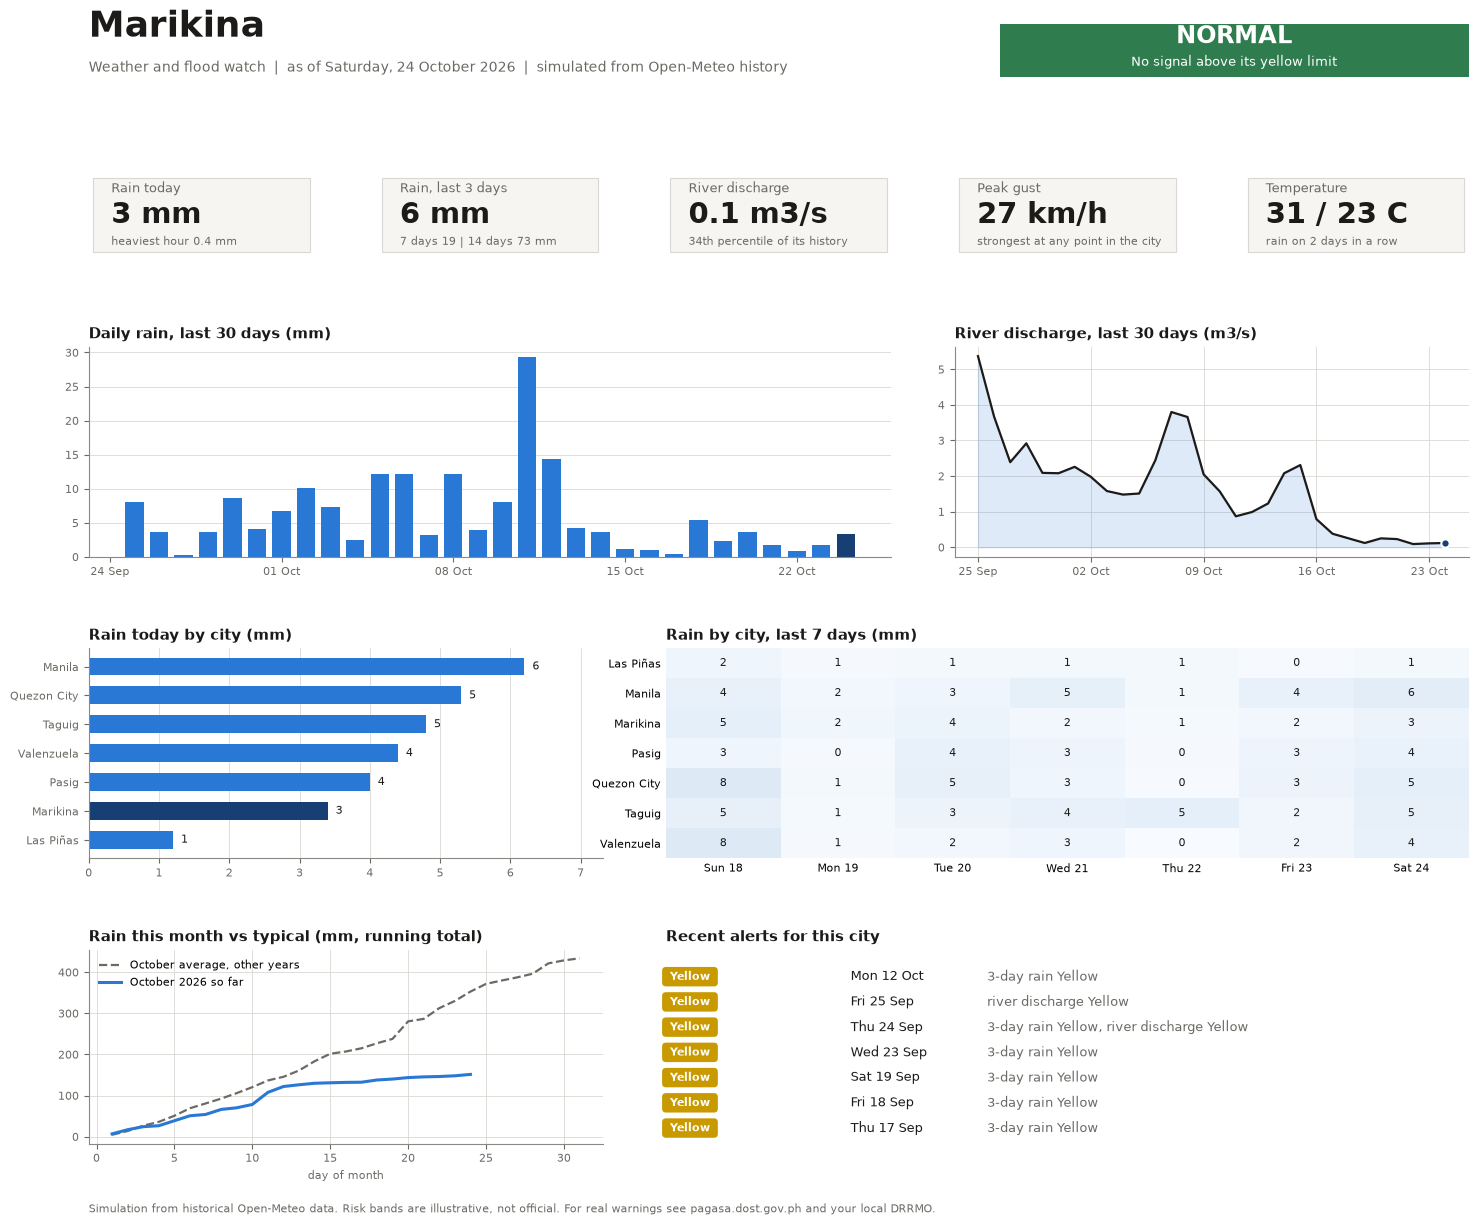

In [5]:
fig = render_dashboard("Marikina", LAST_DAY)
plt.show()

### The heaviest rain day in the data
Pick the city-day with the most rain and replay it.

Heaviest city-day: Marikina 2020-11-11 238 mm


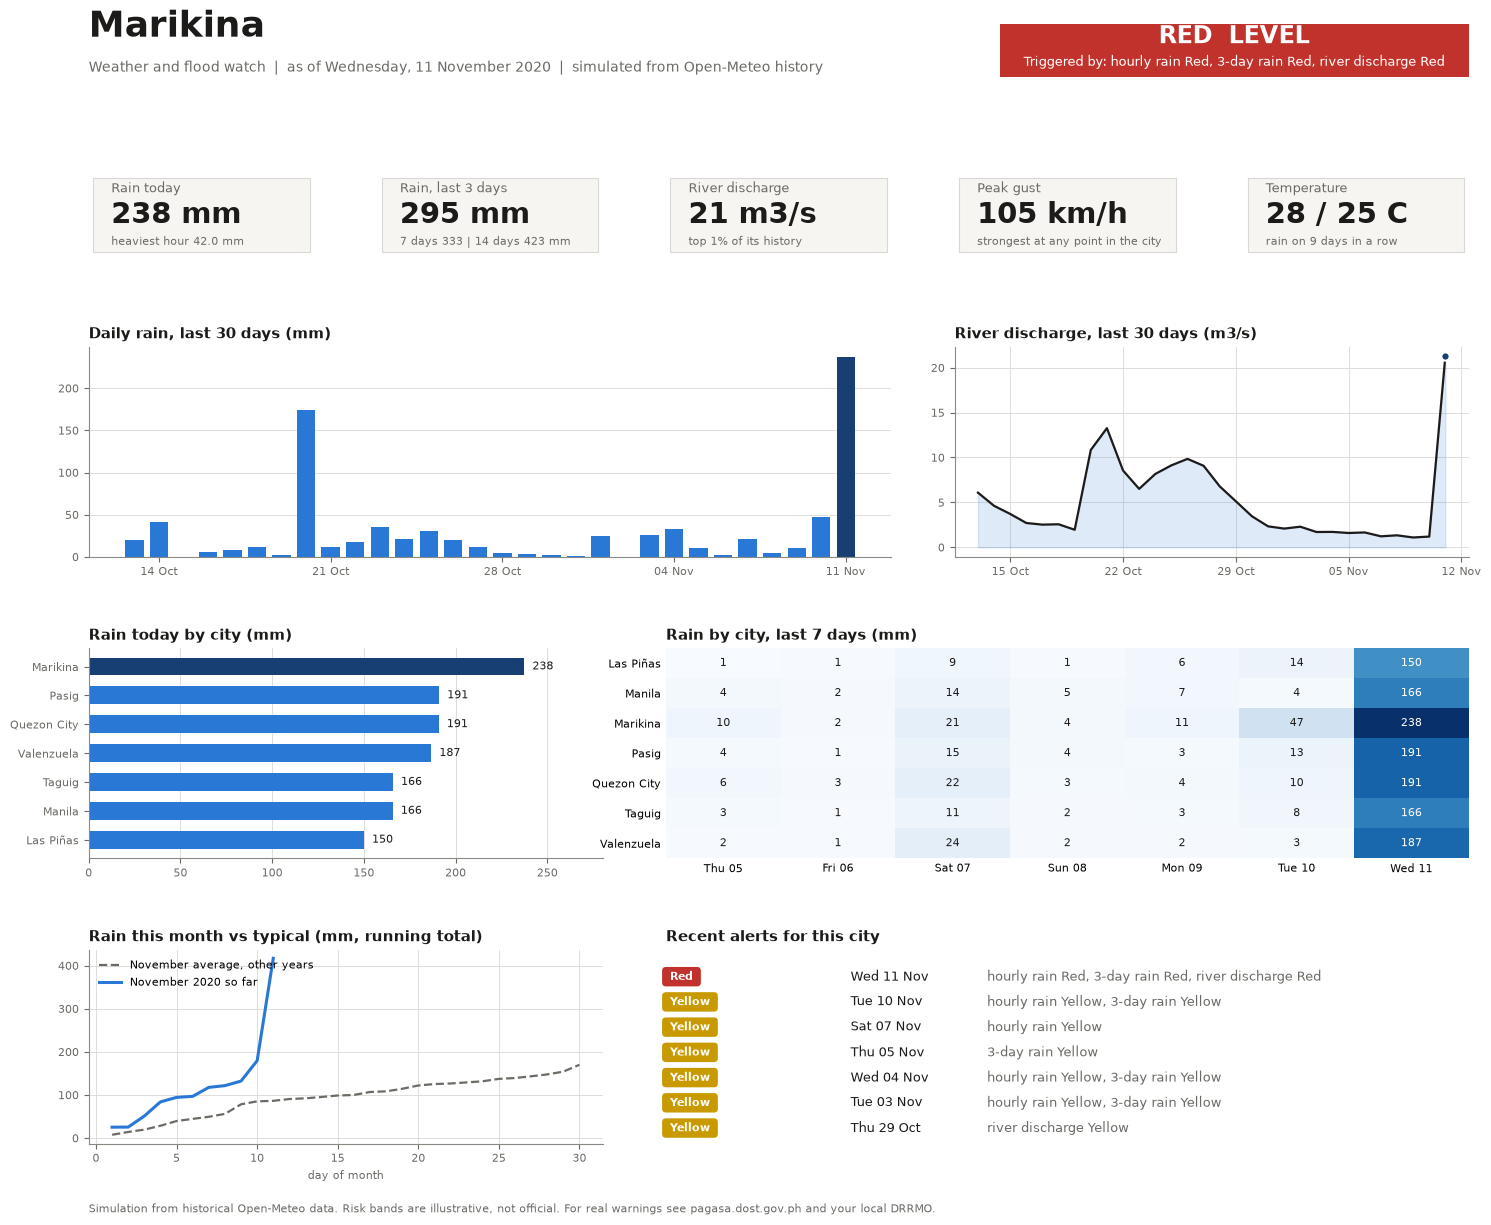

In [6]:
worst = daily.loc[daily["rain_mm"].idxmax()]
print("Heaviest city-day:", worst["city"], worst["date"].date(), f"{worst['rain_mm']:.0f} mm")
fig = render_dashboard(worst["city"], worst["date"])
plt.show()

### A quiet dry-season day, Taguig

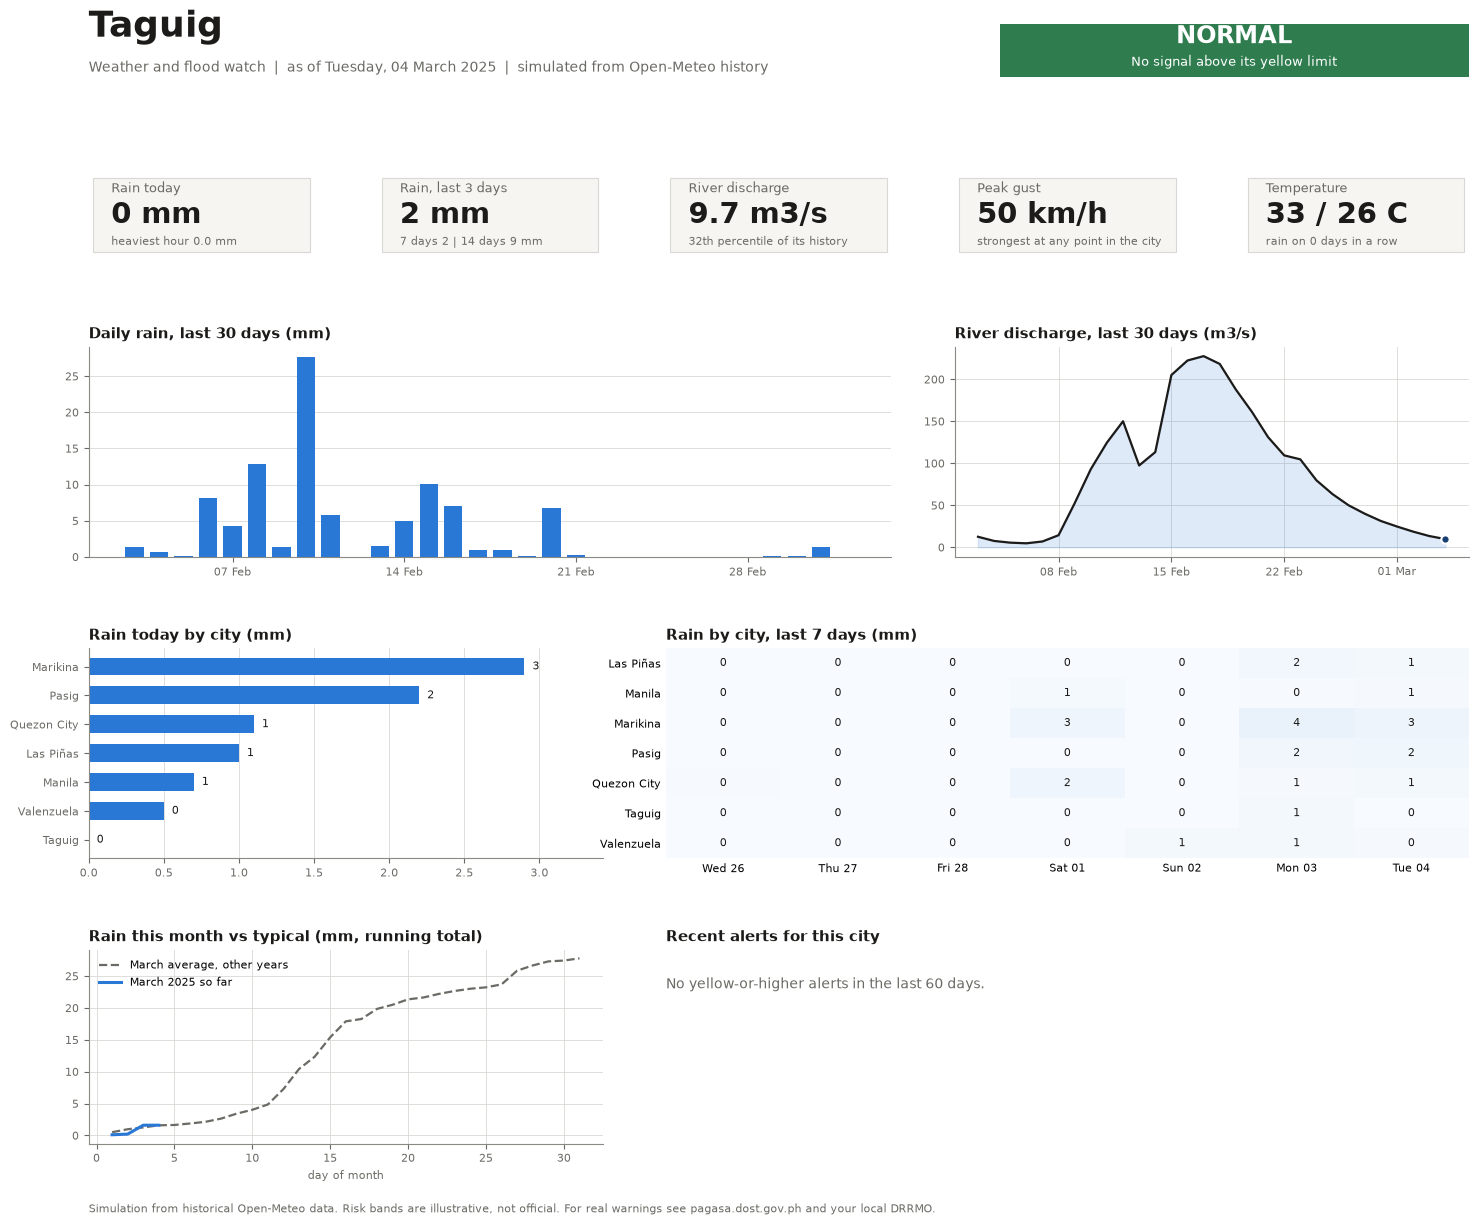

In [7]:
quiet = daily[(daily["city"] == "Taguig") & (daily["date"].dt.month == 3) & (daily["date"].dt.year == 2025)]
quiet_day = quiet.loc[quiet["rain_mm"].idxmin(), "date"]
fig = render_dashboard("Taguig", quiet_day)
plt.show()

## Using it
Change the city and date in `render_dashboard(city, as_of)`. Cities: Las Piñas, Manila, Marikina, Pasig, Quezon City, Taguig, Valenzuela. Dates: 2020-01-01 to 2026-10-24.

For the real app the same panels would be fed by live Open-Meteo forecasts and PAGASA data instead of history, with PAGASA's official level replacing the illustrative bands.